In [ ]:
import zipfile, os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

with zipfile.ZipFile("/images.zip", "r") as z:
  z.extractall("data")

train = pd.read_csv("/train_labels.csv")
sample = pd.read_csv("/SampleSubmission.csv")


print(train.head())
print("Train Shape:", train.shape)
print("Test shape:", sample.shape)
print(train["target"].value_counts())
print(train["target"].value_counts(normalize=True))
print(os.listdir("data")[:5])


                                image  target
0  tfymlmdkpzkqdjhdxyhnoeuqszxphw.jpg       0
1  rxgismgsvmaayzjarbfjaljhqmpbrt.jpg       1
2  uuzshfrhkgrkolhwdvliqauzulurnz.jpg       0
3  mjspxsagzusaznvnyxgamtrlqkqklp.jpg       0
4  rlbmuajgezfiddjzlyeoupxpqubkpt.jpg       1
Train Shape: (1308, 2)
Test shape: (509, 2)
target
0    664
1    644
Name: count, dtype: int64
target
0    0.507645
1    0.492355
Name: proportion, dtype: float64
['images']


In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

All total images in folder: 1817
All train files exist: True
All test files exist: True


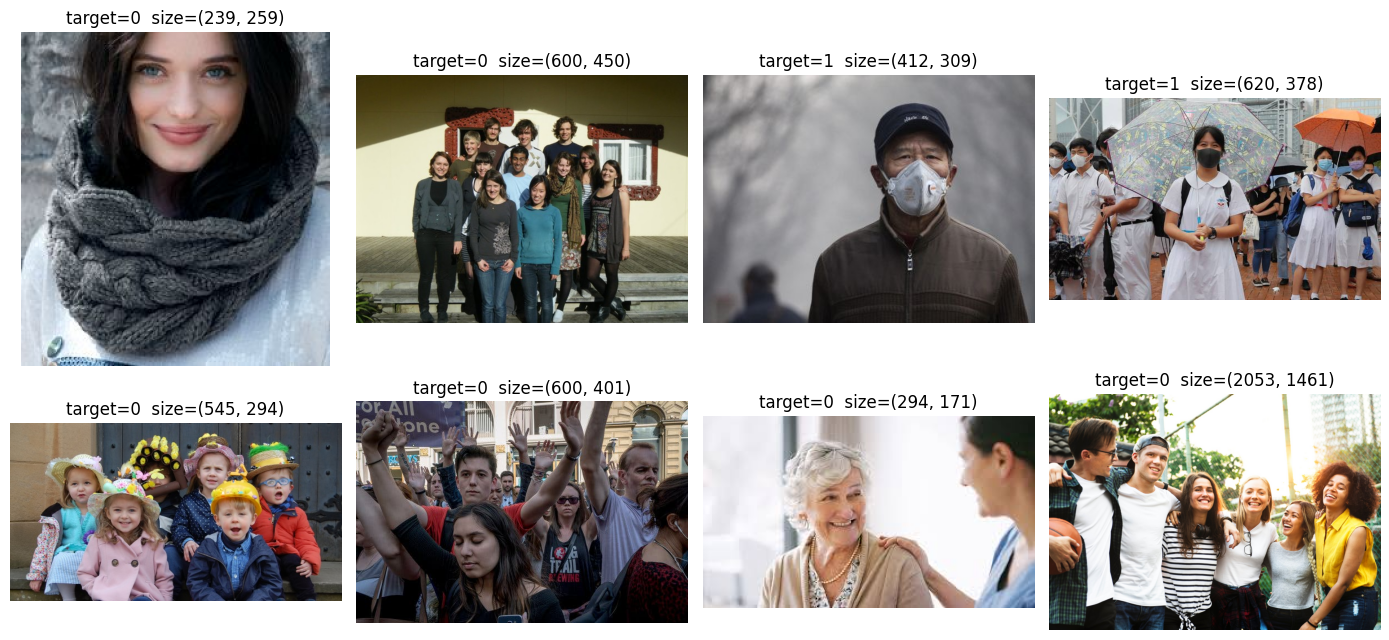

Unique sizes in first 200: 162
[(600, 411), (800, 531), (166, 166), (211, 239), (1500, 1000), (275, 183), (1200, 800), (800, 500), (593, 482), (750, 500)]


In [ ]:
img_dir = "data/images"
files = os.listdir(img_dir)
print("All total images in folder:", len(files))
print("All train files exist:", train["image"].isin(files).all())
print("All test files exist:", sample["image"].isin(files).all())


#Looking at 8 ramodom images with their labels
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.flat, train.sample(8, random_state=42).iterrows()):
    img = Image.open(os.path.join(img_dir, row["image"]))
    ax.imshow(img)
    ax.set_title(f"target={row['target']}  size={img.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

sizes = [Image.open(os.path.join(img_dir, f)).size for f in train["image"].head(200)]
print("Unique sizes in first 200:", len(set(sizes)))
print(sizes[:10])

In [ ]:
import torch
print("Cuda Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
from torch.utils.data import Dataset, dataloader
from torchvision import transforms
from sklearn.model_selection import train_test_split



Cuda Available: True
GPU: Tesla T4


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# 1. Transforms
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

val_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# 2. Dataset
class MaskDataset(Dataset):
    def __init__(self, df, img_dir, tfms, has_labels=True):
        self.df, self.img_dir, self.tfms, self.has_labels = df.reset_index(drop=True), img_dir, tfms, has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(self.img_dir, row["image"])).convert("RGB")
        img = self.tfms(img)
        if self.has_labels:
            return img, torch.tensor(row["target"], dtype=torch.float32)
        return img

# Split: 80% train, 20% validation, keeping the class ratio the same
tr_df, val_df = train_test_split(train, test_size=0.2, stratify=train["target"], random_state=42)

# 3. DataLoaders
train_dl = DataLoader(MaskDataset(tr_df, img_dir, train_tfms), batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(MaskDataset(val_df, img_dir, val_tfms), batch_size=32, shuffle=False, num_workers=2)

# Sanity check: grab one batch
x, y = next(iter(train_dl))
print("Batch images:", x.shape)   # expect [32, 3, 224, 224]
print("Batch labels:", y.shape)   # expect [32]
print("Train size:", len(tr_df), "Val size:", len(val_df))

Using device: cuda
Batch images: torch.Size([32, 3, 224, 224])
Batch labels: torch.Size([32])
Train size: 1046 Val size: 262


**Building the model**

In [ ]:
import torch.nn as nn
from torchvision import models
from sklearn.metrics import roc_auc_score
import numpy as np


model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Replace the final layer: 2048 features -> 1 output (a logit)
model.fc = nn.Linear(model.fc.in_features, 1)
model = model.to(device)

criterion = nn.BCEWithLogitsLoss()   # sigmoid + binary cross-entropy in one

**Training and validation**

In [ ]:
def train_one_epoch(model, dl, optimizer):
    model.train()
    total_loss = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x).squeeze(1)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
    return total_loss / len(dl.dataset)

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    probs, targets, total_loss = [], [], 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        logits = model(x).squeeze(1)
        total_loss += criterion(logits, y).item() * x.size(0)
        probs.extend(torch.sigmoid(logits).cpu().numpy())
        targets.extend(y.cpu().numpy())
    return total_loss / len(dl.dataset), roc_auc_score(targets, probs)

**Phase 1, train the head only**

In [ ]:
# Freeze everything except the new head
for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(model.fc.parameters(), lr=1e-3)

for epoch in range(3):
    tr_loss = train_one_epoch(model, train_dl, optimizer)
    val_loss, val_auc = evaluate(model, val_dl)
    print(f"[Head] Epoch {epoch+1}: train_loss={tr_loss:.4f}  val_loss={val_loss:.4f}  val_AUC={val_auc:.4f}")

[Head] Epoch 1: train_loss=0.6020  val_loss=0.4767  val_AUC=0.9692
[Head] Epoch 2: train_loss=0.4612  val_loss=0.3750  val_AUC=0.9749
[Head] Epoch 3: train_loss=0.3842  val_loss=0.3177  val_AUC=0.9773


**Phase 2, fine_tuning**

In [ ]:
for p in model.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=6)

best_auc = 0
for epoch in range(6):
    tr_loss = train_one_epoch(model, train_dl, optimizer)
    val_loss, val_auc = evaluate(model, val_dl)
    scheduler.step()
    print(f"[Fine-tune] Epoch {epoch+1}: train_loss={tr_loss:.4f}  val_loss={val_loss:.4f}  val_AUC={val_auc:.4f}")
    if val_auc > best_auc:
        best_auc = val_auc
        torch.save(model.state_dict(), "best_model.pt")
        print("   saved new best model")

print("Best val AUC:", best_auc)

[Fine-tune] Epoch 1: train_loss=0.1547  val_loss=0.0595  val_AUC=0.9984
   saved new best model
[Fine-tune] Epoch 2: train_loss=0.0471  val_loss=0.0708  val_AUC=0.9977
[Fine-tune] Epoch 3: train_loss=0.0293  val_loss=0.0500  val_AUC=0.9987
   saved new best model
[Fine-tune] Epoch 4: train_loss=0.0200  val_loss=0.0545  val_AUC=0.9985
[Fine-tune] Epoch 5: train_loss=0.0100  val_loss=0.0478  val_AUC=0.9990
   saved new best model
[Fine-tune] Epoch 6: train_loss=0.0153  val_loss=0.0446  val_AUC=0.9991
   saved new best model
Best val AUC: 0.9990674360319403


**Predictions on the test set**

In [ ]:
# Load the best checkpoint
model.load_state_dict(torch.load("best_model.pt"))
model.eval()

test_ds = MaskDataset(sample, img_dir, val_tfms, has_labels=False)
test_dl = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

@torch.no_grad()
def predict_tta(model, dl):
    all_probs = []
    for x in dl:
        x = x.to(device)
        p1 = torch.sigmoid(model(x).squeeze(1))
        p2 = torch.sigmoid(model(torch.flip(x, dims=[3])).squeeze(1))  # horizontal flip
        all_probs.extend(((p1 + p2) / 2).cpu().numpy())
    return np.array(all_probs)

preds = predict_tta(model, test_dl)

submission = sample.copy()
# The sample file's label column may be named differently; check it:
print(submission.columns.tolist())

['image', 'target']


In [ ]:
submission["target"] = preds
submission.to_csv("submission.csv", index=False)
print(submission.head())
print(submission["target"].describe())


                                image    target
0  aadawlxbmapqrblgxyzarhjasgiobu.png  0.860191
1  abpxvdfyhaaohzcrngcucmhffwizxs.jpg  0.000434
2  aclkjfvackiieiznzfcwienplielrj.jpg  0.998985
3  aelkivmayxgsdjosiibfgmkvfrjvjk.jpg  0.999272
4  aelzzshpfxerelefnkatpczktuxjln.jpg  0.000663
count    509.000000
mean       0.494823
std        0.485906
min        0.000005
25%        0.001129
50%        0.439332
75%        0.998601
max        0.999981
Name: target, dtype: float64
